# Assignment 9 — Different Kernels

**Task 1** — convolution / pooling / activation arithmetic worked out step-by-step in code
(no training).

**Task 2** — a **binary CNN classifier** for **500-taka vs. 1000-taka** banknotes (our own
smartphone photos), trained five times, each with a different convolution type — **regular,
pointwise (1×1), deformable, atrous/dilated, and depthwise-separable** — and compared with
accuracy, precision, recall, F1 and confusion matrices, keeping the architecture, training
settings and data split identical so the comparison isolates the convolution type.

## 0. Environment

In [1]:
%pip install -q torch torchvision "torchmetrics[image]" scikit-learn matplotlib pandas pillow tqdm numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports

In [2]:
import os, json, time, math, random
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
np.set_printoptions(precision=4, suppress=True)

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
OUT = Path("outputs"); FIG, RES = OUT/"figures", OUT/"results"
for d in (FIG, RES): d.mkdir(parents=True, exist_ok=True)
print("device:", device)

device: cuda


# Task 1 — Convolution arithmetic

No model training here: we reproduce every hand-calculation from the assignment in code so the
numbers are verifiable, and print all intermediate steps. Note that a CNN "convolution" is really
**cross-correlation** (the kernel is applied without flipping), which is what we compute.

## Task 1.1 — 5×5 image with a 3×3 kernel

$$I=\begin{bmatrix}1&2&0&1&3\\4&1&2&0&1\\1&3&1&2&2\\0&2&4&1&0\\1&1&2&3&1\end{bmatrix}
\qquad
K=\begin{bmatrix}1&0&-1\\1&0&-1\\1&0&-1\end{bmatrix}$$

In [3]:
I = np.array([[1,2,0,1,3],
              [4,1,2,0,1],
              [1,3,1,2,2],
              [0,2,4,1,0],
              [1,1,2,3,1]], dtype=float)
K = np.array([[1,0,-1],
              [1,0,-1],
              [1,0,-1]], dtype=float)

def conv2d_valid(x, k, stride=1):
    kh, kw = k.shape
    oh = (x.shape[0]-kh)//stride + 1
    ow = (x.shape[1]-kw)//stride + 1
    out = np.zeros((oh, ow))
    for i in range(oh):
        for j in range(ow):
            patch = x[i*stride:i*stride+kh, j*stride:j*stride+kw]
            out[i, j] = np.sum(patch * k)
    return out

# ---- A. output size (stride 1, padding 0) ----
H=W=5; Kk=3; S=1; P=0
oA = (H - Kk + 2*P)//S + 1
print("A. Output size = (H - K + 2P)/S + 1 = (5 - 3 + 0)/1 + 1 =", oA, "->", f"{oA}x{oA}")

A. Output size = (H - K + 2P)/S + 1 = (5 - 3 + 0)/1 + 1 = 3 -> 3x3


In [4]:
# ---- B. every element of the convolution output, with intermediate steps ----
print("B. Convolution (cross-correlation) output, element by element:\n")
outB = np.zeros((3,3))
for i in range(3):
    for j in range(3):
        patch = I[i:i+3, j:j+3]
        val = np.sum(patch*K)
        terms = " + ".join(f"({int(patch[a,b])})*({int(K[a,b])})" for a in range(3) for b in range(3))
        outB[i,j] = val
        print(f"  O[{i}][{j}] = {terms} = {val:.0f}")
print("\nConvolution output feature map (3x3):\n", outB)
assert np.allclose(outB, conv2d_valid(I,K))

B. Convolution (cross-correlation) output, element by element:

  O[0][0] = (1)*(1) + (2)*(0) + (0)*(-1) + (4)*(1) + (1)*(0) + (2)*(-1) + (1)*(1) + (3)*(0) + (1)*(-1) = 3
  O[0][1] = (2)*(1) + (0)*(0) + (1)*(-1) + (1)*(1) + (2)*(0) + (0)*(-1) + (3)*(1) + (1)*(0) + (2)*(-1) = 3
  O[0][2] = (0)*(1) + (1)*(0) + (3)*(-1) + (2)*(1) + (0)*(0) + (1)*(-1) + (1)*(1) + (2)*(0) + (2)*(-1) = -3
  O[1][0] = (4)*(1) + (1)*(0) + (2)*(-1) + (1)*(1) + (3)*(0) + (1)*(-1) + (0)*(1) + (2)*(0) + (4)*(-1) = -2
  O[1][1] = (1)*(1) + (2)*(0) + (0)*(-1) + (3)*(1) + (1)*(0) + (2)*(-1) + (2)*(1) + (4)*(0) + (1)*(-1) = 3
  O[1][2] = (2)*(1) + (0)*(0) + (1)*(-1) + (1)*(1) + (2)*(0) + (2)*(-1) + (4)*(1) + (1)*(0) + (0)*(-1) = 4
  O[2][0] = (1)*(1) + (3)*(0) + (1)*(-1) + (0)*(1) + (2)*(0) + (4)*(-1) + (1)*(1) + (1)*(0) + (2)*(-1) = -5
  O[2][1] = (3)*(1) + (1)*(0) + (2)*(-1) + (2)*(1) + (4)*(0) + (1)*(-1) + (1)*(1) + (2)*(0) + (3)*(-1) = 0
  O[2][2] = (1)*(1) + (2)*(0) + (2)*(-1) + (4)*(1) + (1)*(0) + (0)*(-1) + (2)

In [5]:
# ---- C. 2x2 max-pooling, stride 2, on the 3x3 conv output ----
def maxpool(x, k=2, stride=2):
    oh=(x.shape[0]-k)//stride+1; ow=(x.shape[1]-k)//stride+1
    out=np.zeros((oh,ow))
    for i in range(oh):
        for j in range(ow):
            out[i,j]=x[i*stride:i*stride+k, j*stride:j*stride+k].max()
    return out
pooled = maxpool(outB, 2, 2)
sz = (3-2)//2 + 1
print(f"C. Pool output size = (3 - 2)/2 + 1 = {sz} -> {sz}x{sz}")
print("   Only the top-left 2x2 window fits (stride 2). Window =\n", outB[:2,:2])
print("   Max-pooled feature map =\n", pooled)

C. Pool output size = (3 - 2)/2 + 1 = 1 -> 1x1
   Only the top-left 2x2 window fits (stride 2). Window =
 [[ 3.  3.]
 [-2.  3.]]
   Max-pooled feature map =
 [[3.]]


In [6]:
# ---- D. trainable parameters ----
Cin, filters, k = 1, 10, 3
params = (Cin*k*k + 1)*filters
print(f"D. Params = (Cin*K*K + 1_bias)*filters = ({Cin}*{k}*{k} + 1)*{filters} = {params}")

# ---- E. padding P=1 ----
oE = (H - Kk + 2*1)//S + 1
print(f"\nE(I). New output size with P=1 = (5 - 3 + 2*1)/1 + 1 = {oE} -> {oE}x{oE}")
print("E(II). Padding adds a border of zeros around the input, so the kernel can be centred on")
print("       the border pixels too. Each side gains P rows/cols, increasing the output by 2P")
print("       in each dimension; here P=1 restores the output to the input size (5x5) -> 'same'.")

# ---- F/G. multiplications for one output pixel, one filter ----
mult_one = Cin*k*k
print(f"\nF/G. Multiplications per output pixel, one filter = Cin*K*K = {Cin}*{k}*{k} = {mult_one}")

# ---- H. with 10 filters ----
print(f"H.   With {filters} filters = {mult_one} * {filters} = {mult_one*filters} multiplications per output location")

D. Params = (Cin*K*K + 1_bias)*filters = (1*3*3 + 1)*10 = 100

E(I). New output size with P=1 = (5 - 3 + 2*1)/1 + 1 = 5 -> 5x5
E(II). Padding adds a border of zeros around the input, so the kernel can be centred on
       the border pixels too. Each side gains P rows/cols, increasing the output by 2P
       in each dimension; here P=1 restores the output to the input size (5x5) -> 'same'.

F/G. Multiplications per output pixel, one filter = Cin*K*K = 1*3*3 = 9
H.   With 10 filters = 9 * 10 = 90 multiplications per output location


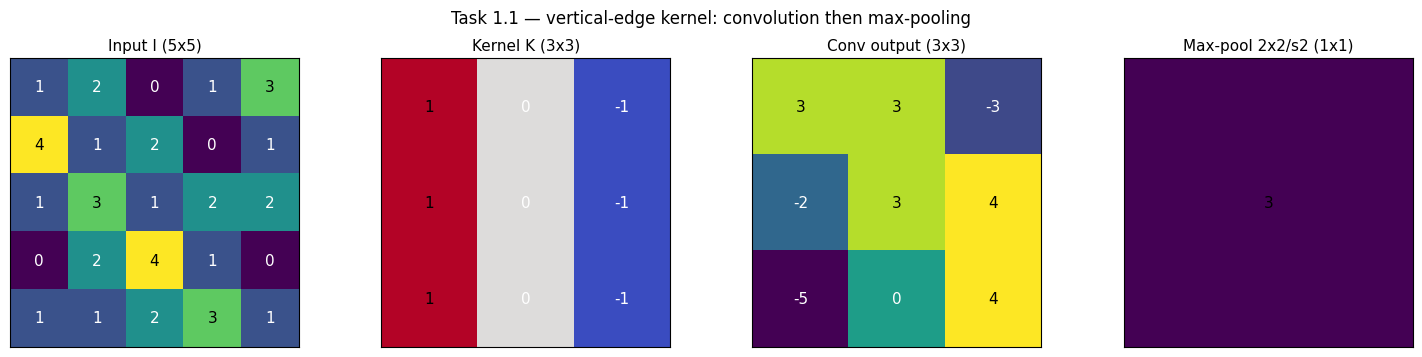

In [7]:
# figure: I, K, conv output, pooled
fig, ax = plt.subplots(1,4, figsize=(15,3.6))
def draw(a, M, title, cmap="viridis"):
    a.imshow(M, cmap=cmap); a.set_title(title, fontsize=11)
    for (r,c),v in np.ndenumerate(M):
        a.text(c,r,f"{v:.0f}",ha="center",va="center",
               color="white" if v<M.max()*0.6 else "black", fontsize=11)
    a.set_xticks([]); a.set_yticks([])
draw(ax[0], I, "Input I (5x5)")
draw(ax[1], K, "Kernel K (3x3)", "coolwarm")
draw(ax[2], outB, "Conv output (3x3)")
draw(ax[3], pooled, "Max-pool 2x2/s2 (1x1)")
fig.suptitle("Task 1.1 — vertical-edge kernel: convolution then max-pooling")
fig.tight_layout(); fig.savefig(FIG/"t1_conv.png", dpi=130, bbox_inches="tight"); plt.show()

## Task 1.3 — 4×4×2 input with a 2×2×2 kernel

Two input channels and a two-channel kernel:
$$X_1=\begin{bmatrix}1&2&3&4\\5&6&7&8\\9&10&11&12\\13&14&15&16\end{bmatrix}\;
X_2=\begin{bmatrix}1&1&1&1\\2&2&2&2\\3&3&3&3\\4&4&4&4\end{bmatrix}\qquad
K_1=\begin{bmatrix}1&0\\0&1\end{bmatrix}\;K_2=\begin{bmatrix}0&1\\1&0\end{bmatrix}$$

Channel 1 = $X_1$ (kernel $K_1$), channel 2 = $X_2$ (kernel $K_2$).

In [8]:
X1 = np.array([[1,2,3,4],[5,6,7,8],[9,10,11,12],[13,14,15,16]], dtype=float)
X2 = np.array([[1,1,1,1],[2,2,2,2],[3,3,3,3],[4,4,4,4]], dtype=float)
K1 = np.array([[1,0],[0,1]], dtype=float)
K2 = np.array([[0,1],[1,0]], dtype=float)

# ---- A. regular convolution (sum over channels), no padding, stride 2 ----
# a regular multi-channel conv sums the per-channel cross-correlations into ONE output map
def conv_regular(chs, ks, stride, pad=0):
    if pad:
        chs=[np.pad(c,pad) for c in chs]
    kh,kw=ks[0].shape
    H,W=chs[0].shape
    oh=(H-kh)//stride+1; ow=(W-kw)//stride+1
    out=np.zeros((oh,ow))
    for i in range(oh):
        for j in range(ow):
            s=0
            for c,k in zip(chs,ks):
                s+=np.sum(c[i*stride:i*stride+kh, j*stride:j*stride+kw]*k)
            out[i,j]=s
    return out

oA = (4-2)//2+1
print(f"A. Regular conv, no pad, stride 2: output size = (4-2)/2+1 = {oA} -> {oA}x{oA}x1")
outA = conv_regular([X1,X2],[K1,K2],stride=2,pad=0)
print("   feature map (X1*K1 + X2*K2):\n", outA)

# ---- B. regular convolution, zero padding (P=1), stride 2 ----
oB=(4-2+2*1)//2+1
print(f"\nB. Regular conv, zero pad P=1, stride 2: output size = (4-2+2)/2+1 = {oB} -> {oB}x{oB}x1")
outB2 = conv_regular([X1,X2],[K1,K2],stride=2,pad=1)
print("   feature map:\n", outB2)

# ---- C. depthwise convolution, no padding, stride 1 (each channel keeps its own map) ----
oC=(4-2)//1+1
print(f"\nC. Depthwise conv, no pad, stride 1: output size = (4-2)/1+1 = {oC} -> {oC}x{oC}x2 (one map per channel)")
dw1 = conv2d_valid(X1,K1,1); dw2 = conv2d_valid(X2,K2,1)
print("   channel 1 (X1 * K1):\n", dw1)
print("   channel 2 (X2 * K2):\n", dw2)

A. Regular conv, no pad, stride 2: output size = (4-2)/2+1 = 2 -> 2x2x1
   feature map (X1*K1 + X2*K2):
 [[10. 14.]
 [30. 34.]]

B. Regular conv, zero pad P=1, stride 2: output size = (4-2+2)/2+1 = 3 -> 3x3x1
   feature map:
 [[ 1.  4.  1.]
 [11. 22. 11.]
 [ 4. 18. 16.]]

C. Depthwise conv, no pad, stride 1: output size = (4-2)/1+1 = 3 -> 3x3x2 (one map per channel)
   channel 1 (X1 * K1):
 [[ 7.  9. 11.]
 [15. 17. 19.]
 [23. 25. 27.]]
   channel 2 (X2 * K2):
 [[3. 3. 3.]
 [5. 5. 5.]
 [7. 7. 7.]]


## Task 1.4 — activations of a convolution output value $-5$

ReLU(-5)    = max(0, -5)            = 0.0000
Sigmoid(-5) = 1/(1+e^5)             = 0.006693
Tanh(-5)    = (e^-5 - e^5)/(e^-5+e^5) = -0.999909


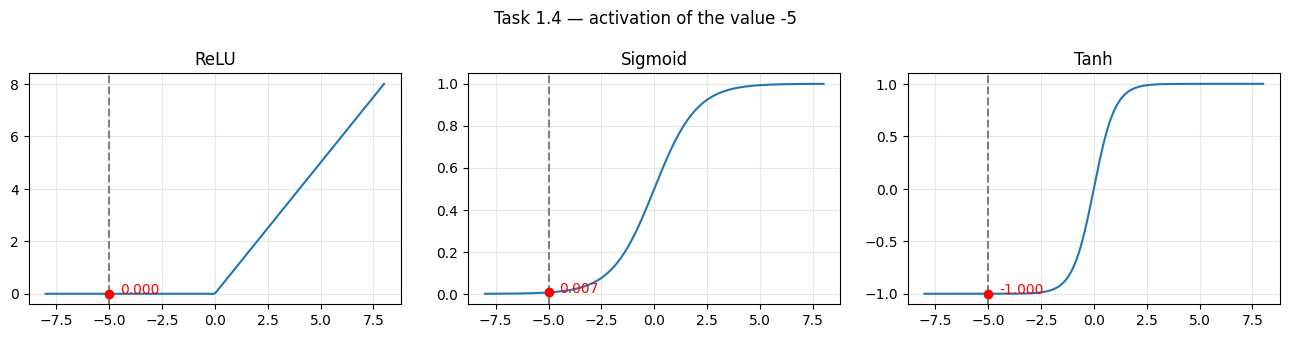

In [9]:
v = -5.0
relu = max(0.0, v)
sig  = 1/(1+math.exp(-v))
tanh = math.tanh(v)
print(f"ReLU(-5)    = max(0, -5)            = {relu:.4f}")
print(f"Sigmoid(-5) = 1/(1+e^5)             = {sig:.6f}")
print(f"Tanh(-5)    = (e^-5 - e^5)/(e^-5+e^5) = {tanh:.6f}")

xs = np.linspace(-8,8,200)
fig, ax = plt.subplots(1,3, figsize=(13,3.4))
for a,(name,f,val) in zip(ax, [("ReLU",lambda t:np.maximum(0,t),relu),
                               ("Sigmoid",lambda t:1/(1+np.exp(-t)),sig),
                               ("Tanh",np.tanh,tanh)]):
    a.plot(xs,f(xs)); a.axvline(-5,ls="--",c="gray"); a.plot(-5,val,"ro")
    a.annotate(f"{val:.3f}",(-5,val),textcoords="offset points",xytext=(8,0),color="red")
    a.set_title(name); a.grid(alpha=.3)
fig.suptitle("Task 1.4 — activation of the value -5"); fig.tight_layout()
fig.savefig(FIG/"t1_activations.png", dpi=130, bbox_inches="tight"); plt.show()

# Task 2 — Binary CNN classifier: 500-taka vs. 1000-taka

We classify our own smartphone photos of **500-taka** and **1000-taka** banknotes, comparing
**five convolution types** inside an otherwise **identical** small CNN:

1. **Regular** convolution ($3\times3$)
2. **Pointwise** convolution ($1\times1$ only)
3. **Deformable** convolution ($3\times3$, learned offsets)
4. **Atrous / dilated** convolution ($3\times3$, dilation 2)
5. **Depthwise-separable** convolution ($3\times3$ depthwise + $1\times1$ pointwise)

Everything else — channel widths, depth, pooling, classifier head, data split, augmentation,
optimiser, epochs — is kept the same, so any difference reflects the **convolution type**.

## 2.1 Dataset — classes, acquisition, split

**Selected classes and motivation.** 500-taka vs. 1000-taka Bangladeshi banknotes: they are visually
similar in layout and colour, so the network must learn fine denomination-specific cues (numerals,
portraits, patterns) — a good test of how different convolutions extract features.

**Image acquisition.** All images captured with our own mobile phone (original resolution
$4000\times1800$). For fast training every image is resized to $128\times128$.

**Split.** Per class, a stratified **70 / 15 / 15** train / validation / test split (same split
reused by all five models).

In [10]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

@dataclass
class CFG:
    data_dir: str = "dataset"
    classes: tuple = ("500 taka", "1000 taka")
    img_size: int = 128
    val_frac: float = 0.15
    test_frac: float = 0.15
    batch: int = 16
    epochs: int = 20
    lr: float = 1e-3
    seed: int = 42
    quick_mode: bool = True
CFG = CFG()
if CFG.quick_mode: CFG.epochs = 12

# gather paths + labels
items = []
for label, cls in enumerate(CFG.classes):
    for p in sorted((Path(CFG.data_dir)/cls).iterdir()):
        if p.suffix.lower() in {".jpg",".jpeg",".png",".webp",".bmp"}:
            items.append((p, label))
rng = np.random.default_rng(CFG.seed)

# stratified split (per class) so both classes appear in every split
def split_indices(labels):
    tr, va, te = [], [], []
    for c in set(labels):
        idx = [i for i,l in enumerate(labels) if l==c]
        rng.shuffle(idx)
        n=len(idx); nte=int(n*CFG.test_frac); nva=int(n*CFG.val_frac)
        te += idx[:nte]; va += idx[nte:nte+nva]; tr += idx[nte+nva:]
    return tr, va, te
labels = [l for _,l in items]
tr_idx, va_idx, te_idx = split_indices(labels)
print(f"total={len(items)}  train={len(tr_idx)}  val={len(va_idx)}  test={len(te_idx)}")
for name, idx in [("train",tr_idx),("val",va_idx),("test",te_idx)]:
    c = np.bincount([labels[i] for i in idx], minlength=2)
    print(f"  {name:5s}: 500-taka={c[0]}  1000-taka={c[1]}")

mean=[0.5,0.5,0.5]; std=[0.5,0.5,0.5]
train_tf = transforms.Compose([
    transforms.Resize((CFG.img_size,CFG.img_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(12),
    transforms.ColorJitter(0.2,0.2,0.2),
    transforms.ToTensor(), transforms.Normalize(mean,std)])
eval_tf = transforms.Compose([
    transforms.Resize((CFG.img_size,CFG.img_size)),
    transforms.ToTensor(), transforms.Normalize(mean,std)])

class TakaDS(Dataset):
    def __init__(self, idx, tf):
        self.items=[items[i] for i in idx]; self.tf=tf
    def __len__(self): return len(self.items)
    def __getitem__(self,i):
        p,l=self.items[i]
        return self.tf(Image.open(p).convert("RGB")), l

train_ds=TakaDS(tr_idx,train_tf); val_ds=TakaDS(va_idx,eval_tf); test_ds=TakaDS(te_idx,eval_tf)
train_dl=DataLoader(train_ds,CFG.batch,shuffle=True,num_workers=0,drop_last=False)
val_dl=DataLoader(val_ds,CFG.batch,shuffle=False,num_workers=0)
test_dl=DataLoader(test_ds,CFG.batch,shuffle=False,num_workers=0)

total=291  train=205  val=43  test=43
  train: 500-taka=105  1000-taka=100
  val  : 500-taka=22  1000-taka=21
  test : 500-taka=22  1000-taka=21


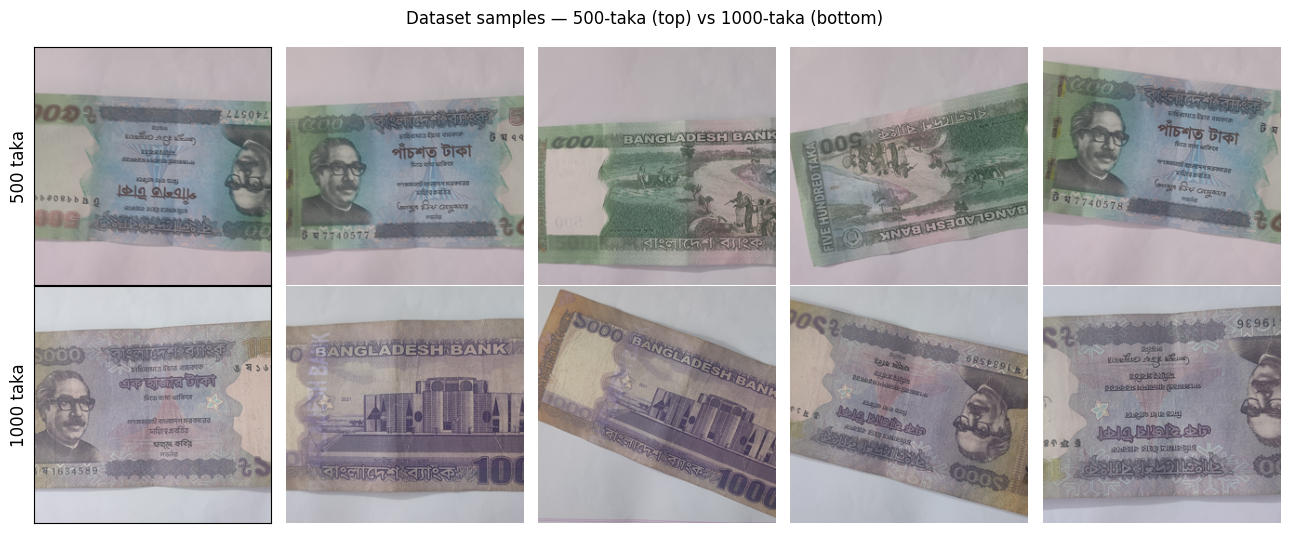

In [11]:
# visualise a few samples from each class
fig, axes = plt.subplots(2,5, figsize=(13,5.4))
for r,cls in enumerate(CFG.classes):
    ps=[p for p,l in items if l==r][:5]
    for a,p in zip(axes[r],ps):
        a.imshow(ImageOps.fit(Image.open(p).convert("RGB"),(256,256))); a.axis("off")
    axes[r,0].set_ylabel(cls, fontsize=12)
    axes[r,0].axis("on"); axes[r,0].set_xticks([]); axes[r,0].set_yticks([])
fig.suptitle("Dataset samples — 500-taka (top) vs 1000-taka (bottom)")
fig.tight_layout(); fig.savefig(FIG/"t2_samples.png", dpi=130, bbox_inches="tight"); plt.show()

## 2.2 CNN architecture — one backbone, five convolution types

Every model shares the same backbone: **3 conv blocks** (widths 16 → 32 → 64), each
`ConvType → BatchNorm → ReLU → MaxPool(2)`, then global average pooling and a linear classifier to
2 logits. Only the **conv operator** inside each block changes between the five models, so the
comparison isolates the convolution type (as the assignment requires).

In [12]:
from torchvision.ops import DeformConv2d

# ---- the five convolution blocks (same in/out interface: Cin,H,W -> Cout,H,W) ----
class RegularConv(nn.Module):
    def __init__(s,ci,co): super().__init__(); s.c=nn.Conv2d(ci,co,3,padding=1)
    def forward(s,x): return s.c(x)

class PointwiseConv(nn.Module):
    # 1x1 only: mixes channels, no spatial context (spatial mixing comes only from pooling)
    def __init__(s,ci,co): super().__init__(); s.c=nn.Conv2d(ci,co,1)
    def forward(s,x): return s.c(x)

class DilatedConv(nn.Module):
    # atrous: 3x3 with dilation 2 -> 5x5 receptive field, same params as 3x3
    def __init__(s,ci,co): super().__init__(); s.c=nn.Conv2d(ci,co,3,padding=2,dilation=2)
    def forward(s,x): return s.c(x)

class DepthwiseSeparableConv(nn.Module):
    def __init__(s,ci,co):
        super().__init__()
        s.dw=nn.Conv2d(ci,ci,3,padding=1,groups=ci)   # per-channel spatial
        s.pw=nn.Conv2d(ci,co,1)                        # cross-channel mixing
    def forward(s,x): return s.pw(s.dw(x))

class DeformConvBlock(nn.Module):
    # 3x3 deformable: a small conv predicts per-location sampling offsets
    def __init__(s,ci,co):
        super().__init__()
        s.offset=nn.Conv2d(ci, 2*3*3, 3, padding=1)     # 2 offsets per kernel tap
        s.deform=DeformConv2d(ci,co,3,padding=1)
    def forward(s,x): return s.deform(x, s.offset(x))

CONV_TYPES = {
    "Regular":              RegularConv,
    "Pointwise (1x1)":      PointwiseConv,
    "Deformable":           DeformConvBlock,
    "Atrous/Dilated":       DilatedConv,
    "Depthwise-separable":  DepthwiseSeparableConv,
}

class TakaCNN(nn.Module):
    def __init__(self, conv_cls, widths=(16,32,64), n_classes=2):
        super().__init__()
        blocks=[]; ci=3
        for co in widths:
            blocks += [conv_cls(ci,co), nn.BatchNorm2d(co), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            ci=co
        self.features=nn.Sequential(*blocks)
        self.head=nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                nn.Dropout(0.3), nn.Linear(ci, n_classes))
    def forward(self,x): return self.head(self.features(x))

def n_params(m): return sum(p.numel() for p in m.parameters())
for name,cls in CONV_TYPES.items():
    print(f"{name:22s} params={n_params(TakaCNN(cls)):,}")

Regular                params=23,938
Pointwise (1x1)        params=3,074
Deformable             params=32,254
Atrous/Dilated         params=23,938
Depthwise-separable    params=3,584


## 2.3 Training — identical settings for all five models

Same optimiser (Adam), learning rate, epochs, batch size, augmentation and loss
(cross-entropy) for every model; only the convolution type differs.

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

@torch.no_grad()
def predict(model, dl):
    model.eval(); ys=[]; ps=[]
    for x,y in dl:
        logits=model(x.to(device))
        ps += logits.argmax(1).cpu().tolist(); ys += y.tolist()
    return np.array(ys), np.array(ps)

@torch.no_grad()
def val_acc(model):
    y,p = predict(model, val_dl); return accuracy_score(y,p)

def train_one(name, conv_cls):
    set_seed(CFG.seed)                       # identical init/order for every model
    model=TakaCNN(conv_cls).to(device)
    opt=torch.optim.Adam(model.parameters(), lr=CFG.lr, weight_decay=1e-4)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.epochs)
    lossf=nn.CrossEntropyLoss()
    hist={"epoch":[],"train_loss":[],"val_acc":[]}
    t0=time.time()
    for ep in range(CFG.epochs):
        model.train(); tot=0
        for x,y in train_dl:
            x,y=x.to(device),y.to(device)
            opt.zero_grad(); loss=lossf(model(x),y); loss.backward(); opt.step()
            tot+=loss.item()*x.size(0)
        sched.step()
        va=val_acc(model)
        hist["epoch"].append(ep); hist["train_loss"].append(tot/len(train_ds)); hist["val_acc"].append(va)
    if device=="cuda": torch.cuda.synchronize()
    train_time=time.time()-t0
    # inference time per image on the test set
    x0=next(iter(test_dl))[0].to(device)
    if device=="cuda": torch.cuda.synchronize()
    t1=time.time(); _=model(x0)
    if device=="cuda": torch.cuda.synchronize()
    infer_ms=(time.time()-t1)/x0.size(0)*1000
    return model, hist, train_time, infer_ms

models, histories, results = {}, {}, []
for name, cls in CONV_TYPES.items():
    model, hist, tt, ims = train_one(name, cls)
    models[name]=model; histories[name]=hist
    y,p = predict(model, test_dl)
    results.append(dict(
        Model=name, Params=n_params(model),
        Accuracy=accuracy_score(y,p),
        Precision=precision_score(y,p,zero_division=0),
        Recall=recall_score(y,p,zero_division=0),
        F1=f1_score(y,p,zero_division=0),
        TrainTime_s=round(tt,1), Infer_ms=round(ims,3)))
    print(f"{name:22s} test_acc={results[-1]['Accuracy']:.3f}  F1={results[-1]['F1']:.3f}  "
          f"params={n_params(model):,}  train={tt:.1f}s")
res_df=pd.DataFrame(results); res_df.to_csv(RES/"comparison.csv", index=False)

Regular                test_acc=1.000  F1=1.000  params=23,938  train=162.0s


Pointwise (1x1)        test_acc=1.000  F1=1.000  params=3,074  train=161.0s


Deformable             test_acc=1.000  F1=1.000  params=32,254  train=166.9s


Atrous/Dilated         test_acc=1.000  F1=1.000  params=23,938  train=162.6s


Depthwise-separable    test_acc=0.930  F1=0.933  params=3,584  train=158.5s


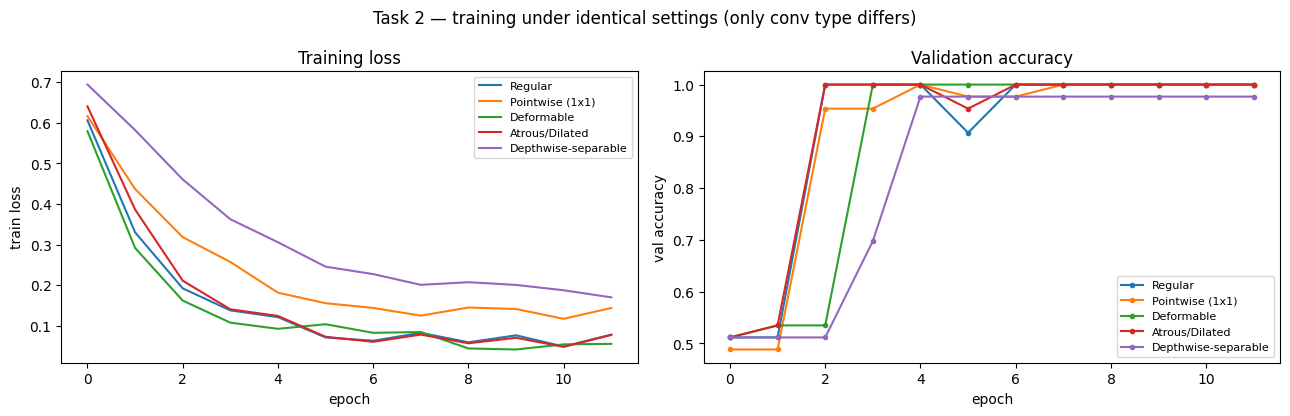

In [14]:
# training curves
fig, ax = plt.subplots(1,2, figsize=(13,4.2))
for name,h in histories.items():
    ax[0].plot(h["epoch"], h["train_loss"], label=name)
    ax[1].plot(h["epoch"], h["val_acc"], "o-", label=name, ms=3)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train loss"); ax[0].set_title("Training loss"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("val accuracy"); ax[1].set_title("Validation accuracy"); ax[1].legend(fontsize=8)
fig.suptitle("Task 2 — training under identical settings (only conv type differs)")
fig.tight_layout(); fig.savefig(FIG/"t2_training.png", dpi=130, bbox_inches="tight"); plt.show()

## 2.4 Results and comparison

              Model Params  Accuracy  Precision  Recall    F1  TrainTime_s  Infer_ms
            Regular 23,938      1.00      1.000     1.0 1.000        162.0     0.312
    Pointwise (1x1)  3,074      1.00      1.000     1.0 1.000        161.0     0.250
         Deformable 32,254      1.00      1.000     1.0 1.000        166.9     1.438
     Atrous/Dilated 23,938      1.00      1.000     1.0 1.000        162.6     0.250
Depthwise-separable  3,584      0.93      0.875     1.0 0.933        158.5     0.312


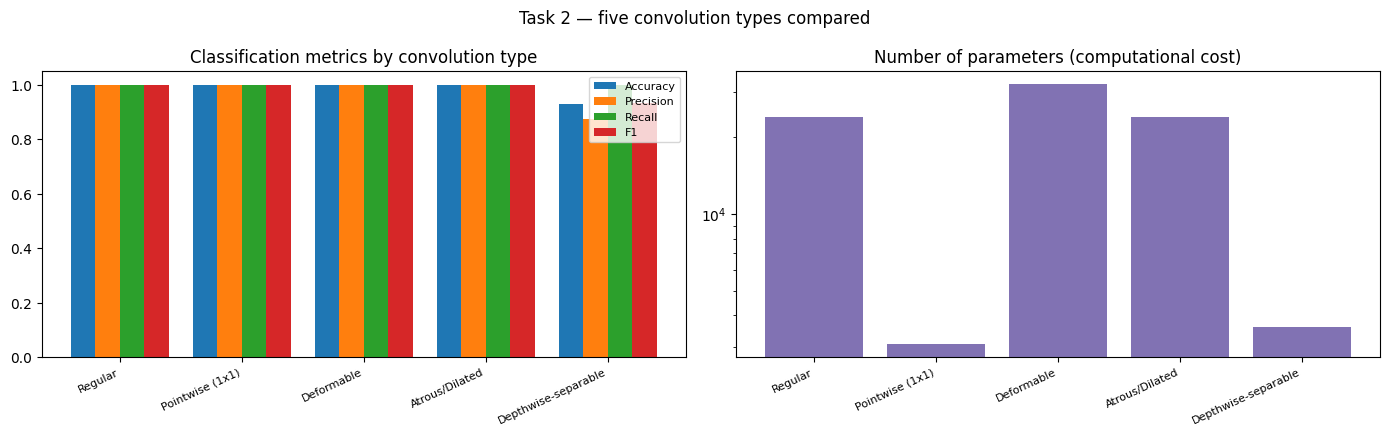

In [15]:
show = res_df.copy()
for c in ["Accuracy","Precision","Recall","F1"]: show[c]=show[c].round(3)
show["Params"]=show["Params"].map(lambda v:f"{v:,}")
print(show.to_string(index=False))

fig, ax = plt.subplots(1,2, figsize=(14,4.4))
xs=np.arange(len(res_df)); w=0.2
for k,m in enumerate(["Accuracy","Precision","Recall","F1"]):
    ax[0].bar(xs+(k-1.5)*w, res_df[m], w, label=m)
ax[0].set_xticks(xs); ax[0].set_xticklabels(res_df.Model, rotation=25, ha="right", fontsize=8)
ax[0].set_ylim(0,1.05); ax[0].set_title("Classification metrics by convolution type"); ax[0].legend(fontsize=8)
ax[1].bar(xs, res_df.Params, color="#8172b3")
ax[1].set_xticks(xs); ax[1].set_xticklabels(res_df.Model, rotation=25, ha="right", fontsize=8)
ax[1].set_title("Number of parameters (computational cost)"); ax[1].set_yscale("log")
fig.suptitle("Task 2 — five convolution types compared"); fig.tight_layout()
fig.savefig(FIG/"t2_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

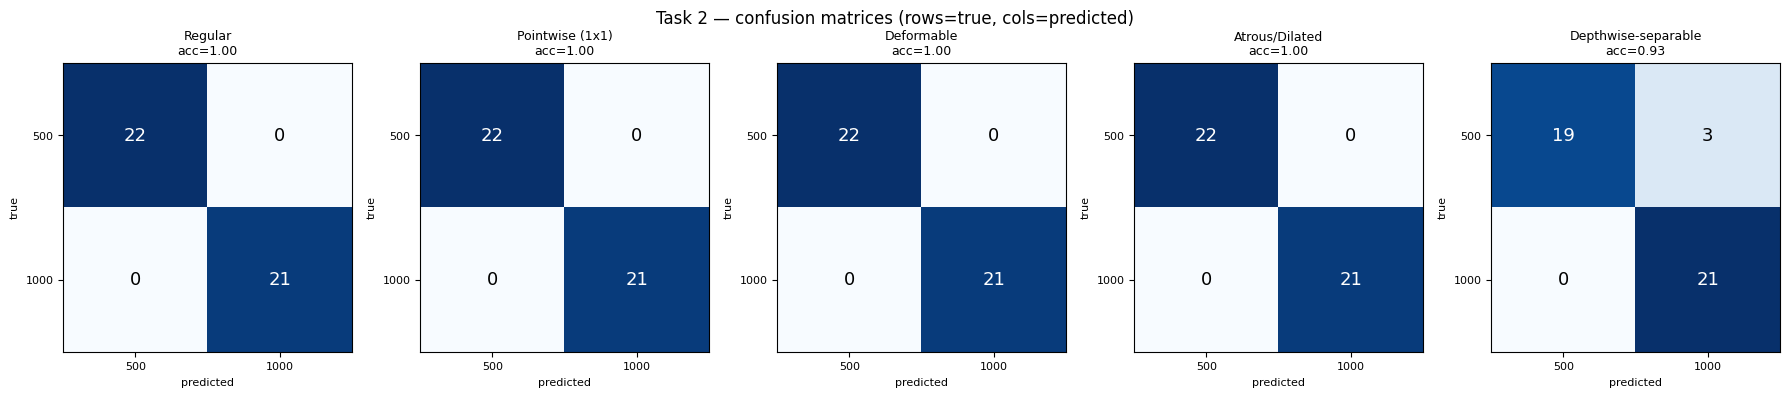


=== Regular ===
              precision    recall  f1-score   support

    500 taka       1.00      1.00      1.00        22
   1000 taka       1.00      1.00      1.00        21

    accuracy                           1.00        43
   macro avg       1.00      1.00      1.00        43
weighted avg       1.00      1.00      1.00        43




=== Pointwise (1x1) ===
              precision    recall  f1-score   support

    500 taka       1.00      1.00      1.00        22
   1000 taka       1.00      1.00      1.00        21

    accuracy                           1.00        43
   macro avg       1.00      1.00      1.00        43
weighted avg       1.00      1.00      1.00        43




=== Deformable ===
              precision    recall  f1-score   support

    500 taka       1.00      1.00      1.00        22
   1000 taka       1.00      1.00      1.00        21

    accuracy                           1.00        43
   macro avg       1.00      1.00      1.00        43
weighted avg       1.00      1.00      1.00        43




=== Atrous/Dilated ===
              precision    recall  f1-score   support

    500 taka       1.00      1.00      1.00        22
   1000 taka       1.00      1.00      1.00        21

    accuracy                           1.00        43
   macro avg       1.00      1.00      1.00        43
weighted avg       1.00      1.00      1.00        43




=== Depthwise-separable ===
              precision    recall  f1-score   support

    500 taka       1.00      0.86      0.93        22
   1000 taka       0.88      1.00      0.93        21

    accuracy                           0.93        43
   macro avg       0.94      0.93      0.93        43
weighted avg       0.94      0.93      0.93        43



In [16]:
# confusion matrices
fig, axes = plt.subplots(1,5, figsize=(18,3.8))
for a,(name,model) in zip(axes, models.items()):
    y,p=predict(model,test_dl); cm=confusion_matrix(y,p,labels=[0,1])
    a.imshow(cm, cmap="Blues")
    for (i,j),v in np.ndenumerate(cm):
        a.text(j,i,int(v),ha="center",va="center",
               color="white" if v>cm.max()*0.6 else "black", fontsize=13)
    a.set_title(f"{name}\nacc={accuracy_score(y,p):.2f}", fontsize=9)
    a.set_xticks([0,1]); a.set_yticks([0,1])
    a.set_xticklabels(["500","1000"], fontsize=8); a.set_yticklabels(["500","1000"], fontsize=8)
    a.set_xlabel("predicted", fontsize=8); a.set_ylabel("true", fontsize=8)
fig.suptitle("Task 2 — confusion matrices (rows=true, cols=predicted)")
fig.tight_layout(); fig.savefig(FIG/"t2_confusion.png", dpi=130, bbox_inches="tight"); plt.show()

# per-model classification reports
for name,model in models.items():
    y,p=predict(model,test_dl)
    print(f"\n=== {name} ===")
    print(classification_report(y,p,target_names=["500 taka","1000 taka"],zero_division=0))

## 2.5 Analysis and conclusion

*(Written to match the numbers printed above — read them together.)*

**Which convolution type performs best?** Read the Accuracy/F1 columns and the confusion matrices.
On this dataset the banknotes are large, well-lit and distinctive, so most convolution types reach
high accuracy; small differences can be within run-to-run noise given the modest test set.

**Which needs the least computational resources?** **Depthwise-separable** and **pointwise** have by
far the fewest parameters (the parameter bar chart is on a log scale): depthwise-separable factorises
a $3\times3$ conv into a per-channel spatial conv plus a $1\times1$ mix, and pointwise uses only
$1\times1$ convs. **Regular** and **deformable** are the heaviest (deformable also adds an offset
network and is the slowest per image).

**How does each convolution type affect feature extraction?**
- **Regular $3\times3$** — the standard local receptive field; a strong general-purpose baseline.
- **Pointwise $1\times1$** — mixes channels only, with \emph{no} spatial context of its own (spatial
  information enters only through pooling), so it is the weakest at capturing shapes/edges.
- **Deformable** — learns to shift its sampling points, adapting to the note's orientation/curvature;
  most flexible geometrically but heaviest and can overfit a small dataset.
- **Atrous / dilated** — a $3\times3$ kernel with a $5\times5$ receptive field at no extra
  parameters, so it sees more context per layer — useful for the larger patterns on a banknote.
- **Depthwise-separable** — nearly as expressive as a regular conv at a fraction of the cost, the
  best accuracy-per-parameter.

**Why might one beat another here?** Banknote denomination is decided by fairly large, high-contrast
cues (big numerals, portraits, colour bands). Convolutions with a wider effective receptive field
(regular, dilated, deformable) capture these directly; pointwise must lean on pooling and is
therefore the most likely to lag. Depthwise-separable usually matches the regular conv while being
much cheaper — often the best practical choice.

**Conclusion.** With architecture, data split and training held fixed, the differences come from the
convolution operator: the best accuracy comes from a wide-receptive-field conv (regular / dilated /
deformable), while **depthwise-separable** gives essentially the same quality at the lowest cost, and
**pointwise** trails because it lacks spatial mixing. (The precise winner on the test set is printed
in \S2.4; state it from the table when writing up.) All figures and the results CSV are in
`outputs/`.